In [10]:
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from dotenv import load_dotenv
from typing import TypedDict, Annotated

load_dotenv()

True

In [4]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

In [8]:
from langchain_openai import ChatOpenAI
import os

@tool
def get_stock_price(symbol: str) -> str:
    '''Return the current price of a stock given the stock symbol.
    :param symbol: The stock symbol
    :return: The current price of the stock as a string.
    '''
    return {
        "MSFT": "200.3",
        "AAPL": "100.4",
        "AMZN": "150.0",
        "RIL": "87.6"
    }.get(symbol,0.0)
    
tools=[get_stock_price]

llm= ChatOpenAI(
    base_url=os.getenv("OCI_LLM_BASE_URL"),
    api_key=os.getenv("OCI_LLM_API_KEY"),
    model=os.getenv("MODEL_QWEN"),
    temperature=0.2
)

llm_with_tools=llm.bind_tools(tools=tools)

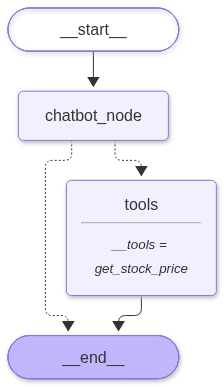

In [17]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


def chatbot(state:State) -> State:
    return {"messages":[llm_with_tools.invoke(state["messages"])]}
    

builder = StateGraph(State)
builder.add_node("chatbot_node",chatbot)
builder.add_node("tools", ToolNode(tools=tools))

builder.add_edge(START, "chatbot_node")
builder.add_conditional_edges("chatbot_node", tools_condition)
builder.add_edge("chatbot_node", END)

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
state=graph.invoke({"messages":[{"role": "user", "content": "I want to buy 15 MSFT stocks. What will be the total price?"}]})
print(state["messages"][-1].content)

200.3
